# Transfer Learning with Function Encoders

**Learning Objectives**
- State the three types of transfer of Ingebrand, Thorpe, and Topcu as regions in coefficient space
- Train a function encoder on quadratics and apply it, with no retraining, to quadratics far outside the training range and to cubics
- Explain the three outcomes with the least-squares projection onto the span of the basis

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/03-function-encoder/03-fe-transfer.ipynb) [![View Slides](https://img.shields.io/badge/View-Presentation-yellow?style=flat-square&logo=googleslides&logoColor=white)](https://raw.githubusercontent.com/kks32-courses/sciml/main/docs/03-function-encoder/b2b.pdf)

This notebook reproduces the polynomial example of Ingebrand, Thorpe, and Topcu, "Function Encoders: A Principled Approach to Transfer Learning in Hilbert Spaces" (ICML 2025, arXiv:2501.18373), Section 4.1 and Figures 1 to 3, which slides 18 and 19 of the course deck show.
Every model trains on quadratics with coefficients in $[-3, 3]$.
A new function then arrives as 100 samples, and each model must represent it with no gradient step.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(0)
print(f"torch {torch.__version__}, dtype {torch.get_default_dtype()}")

torch 2.8.0, dtype torch.float64


## Three types of transfer

<img src="figs/fe-transfer-types.png" width="480" alt="Figure 1 of Ingebrand, Thorpe, and Topcu (2025): the three types of transfer">

Let $f_1, \dots, f_N$ be the training functions and $f$ a new function in the Hilbert space $\mathcal{H}$.
The paper sorts $f$ by where it lies relative to the training set (Definitions 5 to 7 and Figure 1).

Type 1 is interpolation.
The function lies in the convex hull of the training functions, $f = \sum_i w_i f_i$ with $w_i \ge 0$ and $\sum_i w_i = 1$.

Type 2 is extrapolation to the linear span.
Now $f = \sum_i w_i f_i$ with weights of any sign and size, so $f$ can be far larger than any training function.

Type 3 is extrapolation to the Hilbert space.
The function lies outside the span, and no combination of training functions equals it.

For polynomials the picture is concrete.
The quadratic $a x^2 + b x + c$ is the point $(a, b, c) \in \mathbb{R}^3$, and a linear combination of quadratics is the same combination of these points.
The training set fills the cube $[-3, 3]^3$.
A type 1 test quadratic has coefficients in the same cube.
A type 2 test quadratic has coefficients in $[-20, 20]^3$, far outside the cube but in the same three-dimensional space.
A cubic $a x^3 + b x^2 + c x + d$ has a fourth coordinate, so every cubic with $a \ne 0$ is type 3.
The difference between type 2 and type 3 is the difference between a larger quadratic and a new kind of function.

## Training and test functions

Each function is known only through $m = 100$ samples at random points of $[-5, 5]$, and the function encoder fits its coefficients to these samples.
The training loss is measured at 100 further random points of the same function, so a basis with as many functions as samples gains nothing from reproducing the samples alone.
Errors are reported on a grid of 100 equispaced points in $[-5, 5]$.
There are $N = 1000$ training quadratics and 200 test functions of each type.

In [2]:
N, n_test, m, n_grid = 1000, 200, 100, 100
x_grid = np.linspace(-5, 5, n_grid)

def eval_poly(coef, x):
    """Polynomials with coefficients coef (n, p), highest degree first, at x of shape (n, q) or (q,)."""
    powers = np.arange(coef.shape[1] - 1, -1, -1)
    if x.ndim == 1:
        return coef @ (x[None, :] ** powers[:, None])
    return np.sum(coef[:, None, :] * x[..., None] ** powers, axis=-1)

def make_dataset(coef, lo=-5, hi=5):
    xs = rng.uniform(lo, hi, (len(coef), m))       # sample points, where the coefficients are fitted
    xq = rng.uniform(lo, hi, (len(coef), m))       # query points, where the training loss is measured
    grid = np.linspace(lo, hi, n_grid)
    d = dict(xs=xs, ys=eval_poly(coef, xs), xq=xq, yq=eval_poly(coef, xq), yg=eval_poly(coef, grid), xg=grid)
    return {key: torch.tensor(val) for key, val in d.items()}

data = {"train": make_dataset(rng.uniform(-3, 3, (N, 3))),
        "type 1": make_dataset(rng.uniform(-3, 3, (n_test, 3))),
        "type 2": make_dataset(rng.uniform(-20, 20, (n_test, 3))),
        "type 3": make_dataset(rng.uniform(-3, 3, (n_test, 4)))}
x_grid_t = torch.tensor(x_grid)
for name, d in data.items():
    print(f"{name:7s}: {len(d['yg'])} functions, max |f| on the grid {d['yg'].abs().max().item():.1f}")

train  : 1000 functions, max |f| on the grid 89.4
type 1 : 200 functions, max |f| on the grid 86.6
type 2 : 200 functions, max |f| on the grid 586.0
type 3 : 200 functions, max |f| on the grid 434.7


## Function encoder and autoencoder

A function encoder represents a function as $\hat f(x) = \sum_{j=1}^k \alpha_j \phi_j(x)$, where the basis functions $\phi_j$ are the $k$ outputs of one neural network and the coefficients come from least squares on the samples,

$$\alpha = (\Phi^\top \Phi + \lambda I)^{-1} \Phi^\top y, \qquad \Phi_{ij} = \phi_j(x_i), \qquad y_i = f(x_i),$$

with $\lambda = 10^{-6}$ after both matrices are divided by $m$.
Training minimizes the squared error at the query points over batches of training functions, with gradients flowing through the solve (Algorithm 1 of the paper), plus the norm regularizer $\sum_j (\|\phi_j\|^2 - 1)^2$ of its Appendix A.
We train one encoder with $k = 3$ basis functions, the dimension of the quadratics, and one with $k = 100$.

The baseline is an autoencoder with a three-dimensional latent space.
Its encoder maps the 100 grid values of $f$ to $z \in \mathbb{R}^3$, and its decoder maps $z$ back to the grid.
It receives the function on the grid itself, which is more than the function encoder gets.
All networks are MLPs with two hidden layers of width 64 and tanh activations, trained with Adam for 3000 steps in double precision.

In [3]:
class BasisNet(nn.Module):
    """One MLP with k outputs, phi(x) = (phi_1(x), ..., phi_k(x))."""
    def __init__(self, k, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, k))

    def forward(self, x):
        return self.net(x.unsqueeze(-1) / 5.0)

class AutoEncoder(nn.Module):
    """Encoder R^100 -> R^3 and decoder R^3 -> R^100 on the grid, with one fixed output scale."""
    def __init__(self, scale, n_in=n_grid, latent=3, hidden=64):
        super().__init__()
        self.scale = scale
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, n_in))

    def forward(self, y):
        return self.decoder(self.encoder(y / self.scale)) * self.scale

lam = 1e-6

def ls_coefficients(Phi, y):
    """Ridge least squares, batched: Phi (n, m, k), y (n, m) -> alpha (n, k)."""
    G = Phi.transpose(1, 2) @ Phi / Phi.shape[1]
    b = Phi.transpose(1, 2) @ y.unsqueeze(-1) / Phi.shape[1]
    return torch.linalg.solve(G + lam * torch.eye(Phi.shape[2]), b).squeeze(-1)

def fe_predict(model, xs, ys, x_eval):
    """Fit coefficients to the samples (xs, ys) of each function and evaluate on x_eval."""
    with torch.no_grad():
        return ls_coefficients(model(xs), ys) @ model(x_eval).T

def grid_mse(pred, d):
    return torch.mean((pred - d["yg"]) ** 2).item()

n_steps, batch, lr, eval_every = 3000, 50, 1e-3, 100

def train_fe(k):
    torch.manual_seed(0)
    model = BasisNet(k)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr, history = data["train"], {name: [] for name in data}
    for step in range(n_steps + 1):
        if step % eval_every == 0:
            for name, d in data.items():
                history[name].append(grid_mse(fe_predict(model, d["xs"], d["ys"], x_grid_t), d))
        if step == n_steps:
            break
        idx = torch.randint(0, N, (batch,))
        Phi = model(tr["xs"][idx])
        alpha = ls_coefficients(Phi, tr["ys"][idx])
        pred = (model(tr["xq"][idx]) @ alpha.unsqueeze(-1)).squeeze(-1)
        norms = torch.mean(Phi ** 2, dim=1)
        loss = torch.mean((pred - tr["yq"][idx]) ** 2) + torch.mean(torch.sum((norms - 1) ** 2, dim=1))
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model, history

def train_ae():
    torch.manual_seed(0)
    ae = AutoEncoder(scale=data["train"]["yg"].std().item())
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    history = {name: [] for name in data}
    for step in range(n_steps + 1):
        if step % eval_every == 0:
            with torch.no_grad():
                for name, d in data.items():
                    history[name].append(grid_mse(ae(d["yg"]), d))
        if step == n_steps:
            break
        y = data["train"]["yg"][torch.randint(0, N, (batch,))]
        loss = torch.mean((ae(y) - y) ** 2)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return ae, history

In [4]:
models, histories = {}, {}
models["FE (k=3)"], histories["FE (k=3)"] = train_fe(3)
models["FE (k=100)"], histories["FE (k=100)"] = train_fe(100)
models["AE"], histories["AE"] = train_ae()
for label, hist in histories.items():
    print(f"{label:11s}: train MSE {hist['train'][-1]:.3e}")

FE (k=3)   : train MSE 1.639e-03
FE (k=100) : train MSE 1.283e-04
AE         : train MSE 1.839e-01


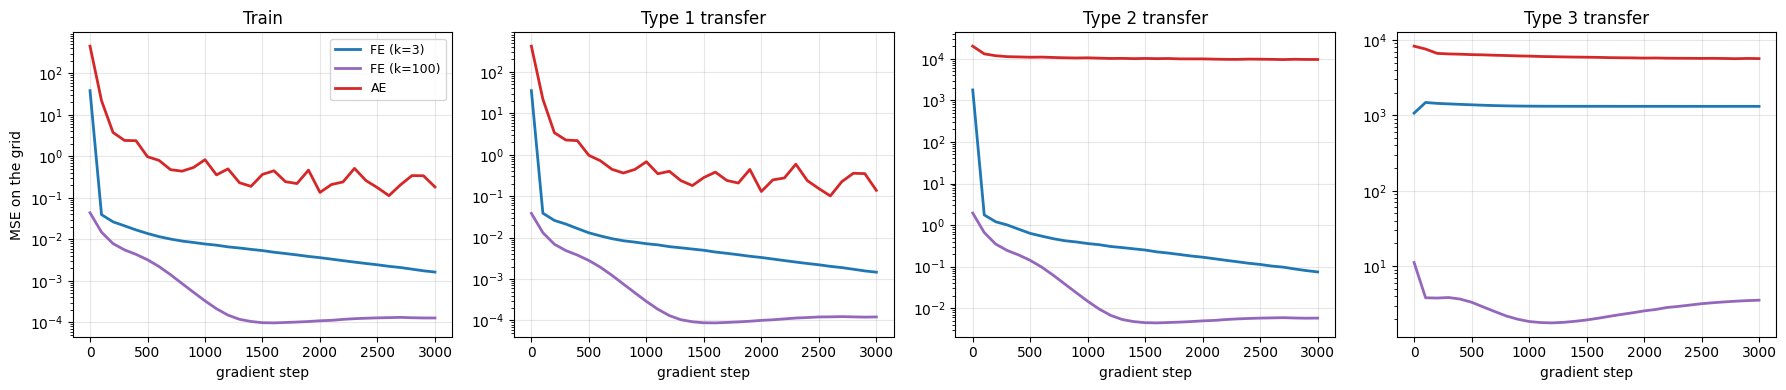

In [5]:
colors = {"FE (k=3)": "tab:blue", "FE (k=100)": "tab:purple", "AE": "tab:red"}
steps = np.arange(0, n_steps + 1, eval_every)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, data):
    for label, hist in histories.items():
        ax.plot(steps, hist[name], color=colors[label], lw=2, label=label)
    ax.set_yscale("log")
    ax.set_title(name.capitalize() + (" transfer" if name != "train" else ""))
    ax.set_xlabel("gradient step")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("MSE on the grid")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

In [6]:
def predict(label, d):
    if label == "AE":
        with torch.no_grad():
            return models["AE"](d["yg"])
    return fe_predict(models[label], d["xs"], d["ys"], x_grid_t)

def rel_err(pred, d):
    return torch.mean(torch.linalg.norm(pred - d["yg"], dim=1) / torch.linalg.norm(d["yg"], dim=1)).item()

print("mean squared error on the grid")
print(f"{'method':12s}" + "".join(f"{name:>11s}" for name in data))
for label in models:
    print(f"{label:12s}" + "".join(f"{grid_mse(predict(label, d), d):11.2e}" for d in data.values()))
print("\nmean relative L2 error on the grid")
print(f"{'method':12s}" + "".join(f"{name:>11s}" for name in data))
for label in models:
    print(f"{label:12s}" + "".join(f"{rel_err(predict(label, d), d):11.2e}" for d in data.values()))

mean squared error on the grid
method            train     type 1     type 2     type 3
FE (k=3)       1.64e-03   1.47e-03   7.47e-02   1.31e+03
FE (k=100)     1.28e-04   1.22e-04   5.79e-03   3.53e+00
AE             1.84e-01   1.39e-01   9.64e+03   5.65e+03

mean relative L2 error on the grid
method            train     type 1     type 2     type 3
FE (k=3)       1.93e-03   1.91e-03   1.94e-03   3.74e-01
FE (k=100)     5.80e-04   5.91e-04   5.69e-04   1.91e-02
AE             2.59e-02   2.53e-02   5.53e-01   6.84e-01


The three example functions below are chosen with the ranges of Figure 3 of the paper.
The type 1 quadratic $2.8x^2 - 0.5x - 3$ reaches 70, the type 2 quadratic $-10.5x^2 + 6x + 8$ reaches $-280$, and the type 3 cubic $x^3 + 2.6x^2 - x$ runs from $-55$ to $185$.
Each function encoder receives 100 random samples of the function, and the autoencoder receives its grid values.

type 1, FE (k=3)   : relative error 1.98e-03
type 1, FE (k=100) : relative error 4.52e-04
type 1, AE         : relative error 1.39e-02
type 2, FE (k=3)   : relative error 1.89e-03
type 2, FE (k=100) : relative error 4.44e-04
type 2, AE         : relative error 5.48e-01
type 3, FE (k=3)   : relative error 3.59e-01
type 3, FE (k=100) : relative error 1.72e-02
type 3, AE         : relative error 6.15e-01


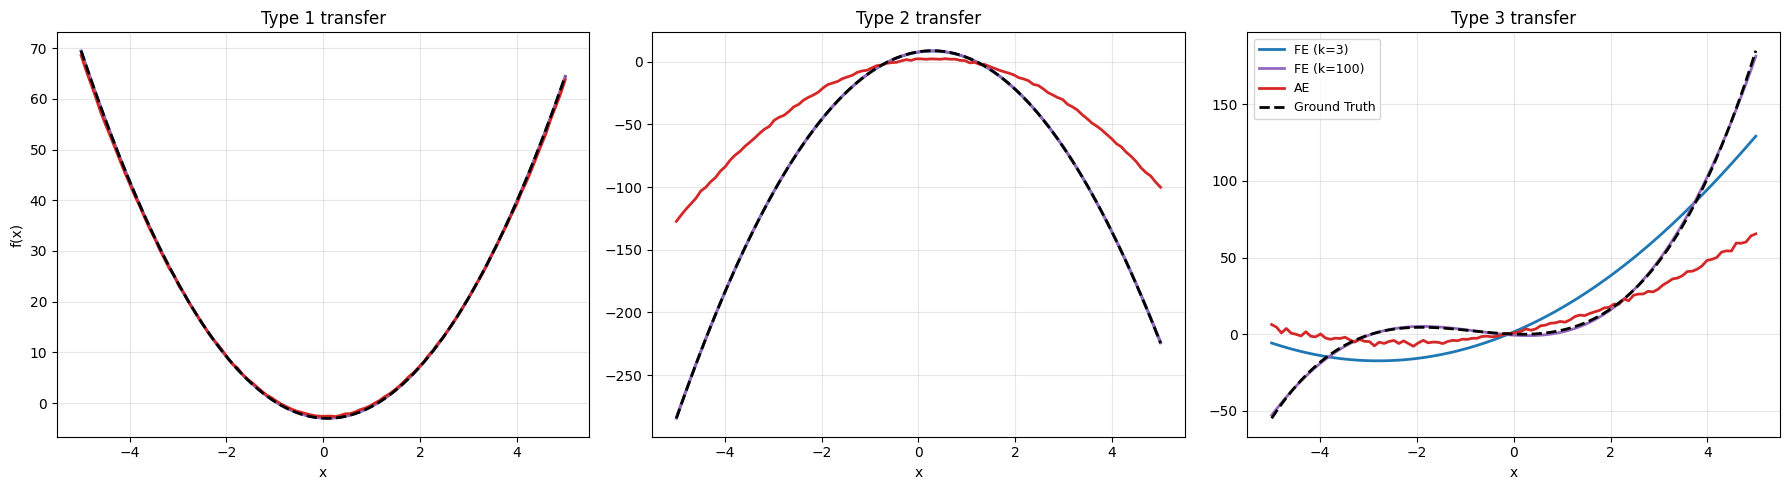

In [7]:
examples = {"type 1": np.array([[2.8, -0.5, -3.0]]),
            "type 2": np.array([[-10.5, 6.0, 8.0]]),
            "type 3": np.array([[1.0, 2.6, -1.0, 0.0]])}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, coef) in zip(axes, examples.items()):
    d = make_dataset(coef)
    for label in models:
        ax.plot(x_grid, predict(label, d)[0], color=colors[label], lw=2, label=label)
    ax.plot(x_grid, d["yg"][0], "k--", lw=2, label="Ground Truth")
    ax.set_title(f"{name.capitalize()} transfer")
    ax.set_xlabel("x")
    ax.grid(True, alpha=0.3)
    for label in models:
        print(f"{name}, {label:11s}: relative error {rel_err(predict(label, d), d):.2e}")
axes[0].set_ylabel("f(x)")
axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()

## Least squares as projection

The least-squares coefficients make $\hat f$ the orthogonal projection of $f$ onto the span of the basis.
Projection is linear.
For $f = a x^2 + b x + c$ the error is $a\,(x^2 - P x^2) + b\,(x - P x) + c\,(1 - P 1)$, so if the span contains $1$, $x$, and $x^2$, every quadratic is reproduced, whatever its coefficients.
Scaling $f$ scales the error by the same factor, which is why type 1 and type 2 have the same relative error in the table.
Training on the cube taught the basis a span, and a span has no boundary.

A cubic lies outside that span.
With $k = 3$ the projection is the best quadratic fit to the cubic, which is the blue curve in the type 3 panel.
With $k = 100$ the span contains the quadratics and 97 further directions, and least squares uses them to follow the cubic, as the caption of Figure 3 of the paper describes.
Those directions were never trained, so this fit depends on the random initialization and on a small $\lambda$.

The autoencoder has no projection.
Its decoder outputs functions near the training set, so it interpolates inside the cube and fails outside it, for the large quadratic and for the cubic alike.
The next cell checks that the span of the three learned basis functions contains the monomials.

In [8]:
x_dense = np.linspace(-5, 5, 1000)
with torch.no_grad():
    Phi3 = models["FE (k=3)"](torch.tensor(x_dense)).numpy()
for p, name in enumerate(["1", "x", "x^2", "x^3"]):
    f = x_dense ** p
    c, *_ = np.linalg.lstsq(Phi3, f, rcond=None)
    print(f"{name:4s}: relative residual after projection onto the span of the k=3 basis {np.linalg.norm(f - Phi3 @ c) / np.linalg.norm(f):.2e}")

1   : relative residual after projection onto the span of the k=3 basis 2.29e-03
x   : relative residual after projection onto the span of the k=3 basis 1.65e-03
x^2 : relative residual after projection onto the span of the k=3 basis 1.23e-03
x^3 : relative residual after projection onto the span of the k=3 basis 4.00e-01


## Extrapolation in $x$

The Hilbert space of the paper is a space of functions on $[-5, 5]$, and the basis was trained there.
The next cell keeps the quadratics of type 1, coefficients in $[-3, 3]$, but samples and evaluates them on $[-10, 10]$.
As a function, such a quadratic is still a combination of $1$, $x$, and $x^2$.
The learned basis is only trained to span them on $[-5, 5]$.
The autoencoder is tied to its grid on $[-5, 5]$ and cannot be evaluated here.

quadratics on [-10, 10], FE (k=3)   : relative error 4.74e-02
quadratics on [-10, 10], FE (k=100) : relative error 8.13e-03


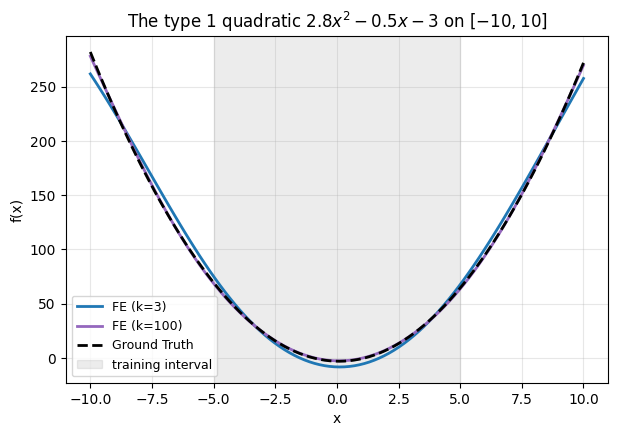

In [9]:
wide = make_dataset(rng.uniform(-3, 3, (n_test, 3)), -10, 10)
for label in ["FE (k=3)", "FE (k=100)"]:
    pred = fe_predict(models[label], wide["xs"], wide["ys"], wide["xg"])
    print(f"quadratics on [-10, 10], {label:11s}: relative error {rel_err(pred, wide):.2e}")

example = make_dataset(np.array([[2.8, -0.5, -3.0]]), -10, 10)
plt.figure(figsize=(7, 4.5))
for label in ["FE (k=3)", "FE (k=100)"]:
    plt.plot(example["xg"], fe_predict(models[label], example["xs"], example["ys"], example["xg"])[0], color=colors[label], lw=2, label=label)
plt.plot(example["xg"], example["yg"][0], "k--", lw=2, label="Ground Truth")
plt.axvspan(-5, 5, color="gray", alpha=0.15, label="training interval")
plt.title("The type 1 quadratic $2.8x^2 - 0.5x - 3$ on $[-10, 10]$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9)
plt.show()

On $[-10, 10]$ the relative error of the three-function encoder rises from $1.91 \times 10^{-3}$ to $4.74 \times 10^{-2}$, and the hundred-function encoder goes from $5.91 \times 10^{-4}$ to $8.13 \times 10^{-3}$.
The fits bend away from the parabola outside the gray band, where the tanh basis functions were never trained.
Type 2 transfer leaves the training range in coefficient space and costs nothing, because the span is the same.
Leaving the training interval in $x$ costs accuracy, because the span of the learned basis is only known on the interval it was trained on.

On the paper's three types, the least-squares encoder has the same relative error on type 1 and type 2, $1.91 \times 10^{-3}$ and $1.94 \times 10^{-3}$ with $k = 3$ and $5.91 \times 10^{-4}$ and $5.69 \times 10^{-4}$ with $k = 100$, while the autoencoder goes from $2.53 \times 10^{-2}$ to $5.53 \times 10^{-1}$.
On type 3 the encoder with $k = 3$ returns the best quadratic fit, with relative error $3.74 \times 10^{-1}$, and the encoder with $k = 100$ reaches $1.91 \times 10^{-2}$.
The span of the $k = 3$ basis contains $1$, $x$, and $x^2$ to residuals of $2.29 \times 10^{-3}$, $1.65 \times 10^{-3}$, and $1.23 \times 10^{-3}$, and the residual of $x^3$ is $4.00 \times 10^{-1}$, the exact value $2/5$ for the quadratics on $[-5, 5]$.